(sec-12-2)=
# 12.2 High-Pass Filtering and Baseline Wander Removal

During an exercise stress test the patient walks on a treadmill while a 12-lead ECG is recorded. The cardiologist watches one thing above all: the level of the ST segment. A horizontal ST depression of 0.1 mV (one small square on standard ECG paper) in two adjacent leads is a classic sign of myocardial ischemia. Yet the same treadmill makes the patient breathe hard and move, and the baseline of the ECG drifts by several tenths of a millivolt, more than the ST change we are looking for. Removing that drift is the first step of almost every ECG pipeline, and it is the step where a careless choice of filter can create or erase the very ST deviation the test is meant to detect.

In this section I compare the main methods for removing baseline wander on one carefully constructed test problem: a clean ECG from MIT-BIH record 100 with real baseline wander from the Noise Stress Test Database added at several noise levels. We start with the high-pass filter, see why its cutoff must stay below the heart-rate fundamental and why a causal filter distorts the ST segment while a zero-phase one does not, make a linear-phase FIR version practical with a decimation trick, and then turn to three ways of *estimating* the baseline and subtracting it: a two-stage median filter, a cubic spline through the PR segments, and simple moving-average and polynomial fits. Every method is judged by the same numbers, including the error it makes in the ST level.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from scipy import signal, ndimage, interpolate

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
rng = np.random.default_rng(42)

(sec-12-2-1)=
## 12.2.1 The Test Signal

### Step 1: Load the clean ECG and the baseline-wander record

We use the same reference segment as in [Section 12.1](01_ecg_noise_types.ipynb), minutes 12 to 17 of record 100 (lead MLII) {cite:p}`moody2001,goldberger2000`, together with the same five minutes of channel `noise1` of the `bw` record of the Noise Stress Test Database {cite:p}`moody1984`. We keep the normal and atrial premature beats that lie at least one second from either end of the segment, so that every beat has a complete PR and ST segment.

In [2]:
fs = 360
seg_from, seg_to = 12 * 60 * fs, 17 * 60 * fs
ecg = wfdb.rdrecord("../data/mitdb/100", sampfrom=seg_from, sampto=seg_to, channels=[0]).p_signal[:, 0]
ann = wfdb.rdann("../data/mitdb/100", "atr", sampfrom=seg_from, sampto=seg_to)
bw = wfdb.rdrecord("../data/nstdb/bw", sampfrom=seg_from, sampto=seg_to, channels=[0]).p_signal[:, 0]
bw = bw - bw.mean()

t = np.arange(ecg.size) / fs
r_peaks = ann.sample[np.isin(ann.symbol, ["N", "A"])] - seg_from
r_peaks = r_peaks[(r_peaks > fs) & (r_peaks < ecg.size - fs)]
print(f"{r_peaks.size} beats, mean RR {np.diff(r_peaks).mean() / fs * 1000:.0f} ms")

372 beats, mean RR 801 ms


### Step 2: Measure the isoelectric level of each beat

Clinically, the reference level of the ECG is the **PR segment**, the short flat stretch between the end of the P wave and the onset of the QRS complex, when no part of the heart is depolarizing or repolarizing. ST deviations are always measured relative to it. In record 100 the P wave peaks about 160 ms before the R peak and the QRS starts about 40 ms before it, so I take the mean of the signal between 100 and 60 ms before each R peak as that beat's PR level. In a real application the R peaks would come from a QRS detector (Section 19.1); here we use the database annotations so that detection errors do not blur the comparison.

In [3]:
PR_WIN = (int(-0.100 * fs), int(-0.060 * fs))        # 100 to 60 ms before R
ST_OFFSET = int(0.110 * fs)                           # ST measurement point, 110 ms after R


def pr_knots(x, r_peaks):
    """Knot times (samples) and PR levels (mV): mean of x over PR_WIN before each R peak."""
    tk = r_peaks + (PR_WIN[0] + PR_WIN[1]) // 2
    yk = np.array([x[r + PR_WIN[0]:r + PR_WIN[1]].mean() for r in r_peaks])
    return tk, yk


def spline_baseline(x, r_peaks):
    """Cubic spline through the PR knots, held constant outside the first and last knot."""
    tk, yk = pr_knots(x, r_peaks)
    n = np.clip(np.arange(x.size), tk[0], tk[-1])
    return interpolate.CubicSpline(tk, yk)(n)

Record 100 is clean, but not perfectly flat: like any real recording it has its own small respiratory wander. If we used it unchanged as the reference, a method that removed this wander would be penalized for doing its job. I therefore define the reference $s[n]$ as record 100 with its own PR-level drift removed by the spline we have just written. Its PR segments sit at zero, so its ST level is the clinical ST deviation. This choice gives the spline method of Section 12.2.6 a small home advantage, which we keep in mind when reading the results.

In [4]:
own_wander = spline_baseline(ecg, r_peaks)
s = ecg - own_wander
print(f"Record 100's own PR-level drift: RMS {np.std(own_wander) * 1000:.0f} uV, "
      f"range {np.ptp(own_wander) * 1000:.0f} uV")

Record 100's own PR-level drift: RMS 45 uV, range 278 uV


### Step 3: Add real baseline wander at several SNRs

We add the `bw` noise with the gain of equation (12.6) from [Section 12.1](01_ecg_noise_types.ipynb), at input SNRs of 12, 6, 0 and $-6$ dB. At $-6$ dB the wander has four times the power of the ECG, which is typical of a patient walking briskly.

In [5]:
def add_noise_at_snr(s, v, snr_db):
    """Return s + g*v with the gain g of equation (18.6)."""
    P_s = np.mean((s - s.mean()) ** 2)
    return s + v * np.sqrt(P_s / (np.mean(v ** 2) * 10 ** (snr_db / 10)))


snr_levels = [12, 6, 0, -6]
noisy = {snr: add_noise_at_snr(s, bw, snr) for snr in snr_levels}
x6 = noisy[6]
print(f"Wander RMS at 6 dB: {np.std(x6 - s) * 1000:.0f} uV, at -6 dB: {np.std(noisy[-6] - s) * 1000:.0f} uV")

Wander RMS at 6 dB: 95 uV, at -6 dB: 377 uV


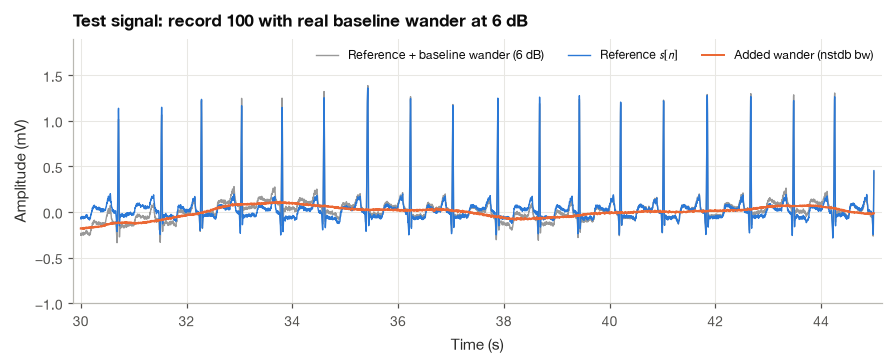

In [6]:
show = (t >= 30) & (t < 45)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(t[show], x6[show], color="0.6", lw=0.9, label="Reference + baseline wander (6 dB)")
ax.plot(t[show], s[show], color=C[0], lw=0.9, label="Reference $s[n]$")
ax.plot(t[show], (x6 - s)[show], color=C[1], lw=1.3, label="Added wander (nstdb bw)")
ax.set(xlabel="Time (s)", ylabel="Amplitude (mV)", title="Test signal: record 100 with real baseline wander at 6 dB")
ax.legend(loc="upper right", ncols=3, fontsize=8)
ax.set_ylim(-1.0, 1.9)
plt.show()

### Step 4: Decide how to score a method

We use the metrics of [Section 12.1](01_ecg_noise_types.ipynb) with one adjustment. A high-pass filter always returns a signal with zero mean, while our reference has its PR segments at zero, so the two differ by a constant that has no clinical meaning. Before computing RMSE and PRD we therefore remove the mean of both signals. To these I add the metric a cardiologist would care about most. For beat $k$ with R peak at sample $r_k$, the **ST level** is the amplitude 110 ms after the R peak minus the PR level of the same beat,

(eq-12-12)=
\begin{equation*}
\mathrm{ST}_k(x) = x[r_k + n_{\text{ST}}] - \frac{1}{|W_{\text{PR}}|}\sum_{m \in W_{\text{PR}}} x[r_k + m], \tag{12.12}
\end{equation*}

where $W_{\text{PR}}$ is the set of offsets from 100 to 60 ms before the R peak. The **ST error** of an estimate $\hat{s}$ is the mean absolute difference $\frac{1}{K}\sum_k |\mathrm{ST}_k(\hat{s}) - \mathrm{ST}_k(s)|$ over all $K$ beats, and the **ST bias** is the mean signed difference. Both are reported in microvolts. A common clinical threshold for a significant ST change is 50 to 100 µV, so an ST error of a few microvolts is harmless and one of several tens is not.

In [7]:
def st_levels(x, r_peaks):
    """ST level of every beat, equation (18.12), in mV."""
    return x[r_peaks + ST_OFFSET] - pr_knots(x, r_peaks)[1]


def score(s_hat, s, x, r_peaks):
    """RMSE, PRD, Delta SNR (mean-removed), ST error and ST bias of an estimate."""
    e = (s_hat - s_hat.mean()) - (s - s.mean())
    P_s, P_in = np.var(s), np.var(x - s)
    d_st = st_levels(s_hat, r_peaks) - st_levels(s, r_peaks)
    return {"RMSE (uV)": 1000 * np.sqrt(np.mean(e ** 2)),
            "PRD (%)": 100 * np.sqrt(np.mean(e ** 2) / P_s),
            "dSNR (dB)": 10 * np.log10(P_in / np.mean(e ** 2)),
            "ST error (uV)": 1000 * np.mean(np.abs(d_st)),
            "ST bias (uV)": 1000 * np.mean(d_st)}


print(f"ST level of the reference: mean {1000 * st_levels(s, r_peaks).mean():.0f} uV")

ST level of the reference: mean -55 uV


Record 100 has a mild ST depression of about 55 µV relative to the PR segment. That is a useful feature for our test: a good baseline method must leave it alone.

(sec-12-2-2)=
## 12.2.2 What a High-Pass Filter Does to an ECG

A high-pass filter passes the fast parts of a signal and attenuates the slow ones ([Section 8.1](../ch13_filter_fundamentals/01_filter_types_specs.ipynb)). The simplest example is the first-order analog high-pass, the RC circuit found in the input stage of many ECG amplifiers. With cutoff $\omega_c = 2\pi f_c$, its transfer function is

(eq-12-13)=
\begin{equation*}
H(s) = \frac{s}{s + \omega_c}. \tag{12.13}
\end{equation*}

Setting $s = j\omega$ gives the frequency response, and we can read off its magnitude and phase separately (Section 15.1 treats higher-order designs).

**Magnitude.** The magnitude of a quotient is the quotient of the magnitudes, and $|j\omega| = \omega$ while $|\omega_c + j\omega| = \sqrt{\omega_c^2 + \omega^2}$, so

(eq-12-14)=
\begin{equation*}
|H(j\omega)| = \frac{\omega}{\sqrt{\omega^2 + \omega_c^2}}. \tag{12.14}
\end{equation*}

At $\omega = \omega_c$ this equals $1/\sqrt{2}$, the familiar $-3$ dB point. Well above the cutoff it approaches one, and well below it falls in proportion to $\omega$, at 20 dB per decade.

**Phase.** The phase of a quotient is the difference of the phases. The numerator $j\omega$ points straight up the imaginary axis, with phase $\pi/2$, and the denominator $\omega_c + j\omega$ has phase $\arctan(\omega/\omega_c)$. Hence

(eq-12-15)=
\begin{equation*}
\angle H(j\omega) = \frac{\pi}{2} - \arctan\frac{\omega}{\omega_c} = \arctan\frac{\omega_c}{\omega}, \tag{12.15}
\end{equation*}

where the last step uses $\arctan a + \arctan(1/a) = \pi/2$ for $a > 0$. The phase is a *lead* that is large at low frequencies and fades away above the cutoff.

This is the root of the trouble. A sinusoid with phase lead $\varphi$ at frequency $f$ is shifted earlier in time by $\varphi/(2\pi f)$. For $f_c = 0.5$ Hz, the heart-rate fundamental of record 100 at 1.25 Hz gets a lead of $\arctan(0.4) = 21.8°$, a time shift of 48 ms, while its fourth harmonic at 5 Hz gets $\arctan(0.1) = 5.7°$, a shift of only 3 ms. Because the components of the beat no longer stay aligned, the beat changes shape, and the slowest parts of the beat (the ST segment and T wave) change most. We check equation (12.15) against the digital filter that `scipy.signal.butter` designs at 360 Hz.

In [8]:
fc = 0.5
b1, a1 = signal.butter(1, fc, "highpass", fs=fs)
for f0 in (1.25, 5.0):
    _, H = signal.freqz(b1, a1, worN=[f0], fs=fs)
    phi_formula = np.degrees(np.arctan(fc / f0))
    print(f"f = {f0:4.2f} Hz: digital phase {np.degrees(np.angle(H[0])):5.2f} deg, "
          f"formula (18.15) {phi_formula:5.2f} deg, time shift {phi_formula / 360 / f0 * 1000:4.1f} ms")

f = 1.25 Hz: digital phase 21.80 deg, formula (18.15) 21.80 deg, time shift 48.4 ms
f = 5.00 Hz: digital phase  5.71 deg, formula (18.15)  5.71 deg, time shift  3.2 ms


### Choosing the cutoff

The ECG is close to periodic, so its spectrum consists of harmonics of the heart rate, and the lowest of them sits at the heart rate itself, $f_{\text{HR}} = \text{HR}/60$. A cutoff above $f_{\text{HR}}$ would attenuate and shift the fundamental, which carries the overall shape of the beat. The cutoff must therefore satisfy

(eq-12-16)=
\begin{equation*}
f_c < f_{\text{HR,min}} = \frac{\text{HR}_{\min}}{60}, \tag{12.16}
\end{equation*}

and for a heart rate that can fall to 40 beats per minute, this gives $f_c < 0.67$ Hz. The AHA/ACCF/HRS recommendations for the standardization of the ECG {cite:p}`kligfield2007` translate this into two numbers. For conventional causal filters, whose phase lead reaches well above the cutoff, the low-frequency cutoff should be 0.05 Hz so that the phase distortion at the heart rate stays negligible. Digital filters with zero or linear phase, which do not distort the timing, may use a cutoff up to 0.67 Hz. Monitoring equipment, which needs a steady trace more than an exact ST level, commonly uses 0.5 Hz. I use 0.5 Hz below, the value most often met in practice.

In [9]:
sos_c1 = signal.butter(1, 0.5, "highpass", fs=fs, output="sos")     # causal, 1st order
sos_c2 = signal.butter(2, 0.5, "highpass", fs=fs, output="sos")     # causal, 2nd order
sos_005 = signal.butter(2, 0.05, "highpass", fs=fs, output="sos")   # diagnostic cutoff

f = np.logspace(-2.3, 1.5, 600)
resp = {}
for name, sos in [("0.5 Hz, 1st order", sos_c1), ("0.5 Hz, 2nd order", sos_c2), ("0.05 Hz, 2nd order", sos_005)]:
    resp[name] = signal.sosfreqz(sos, worN=f, fs=fs)[1]

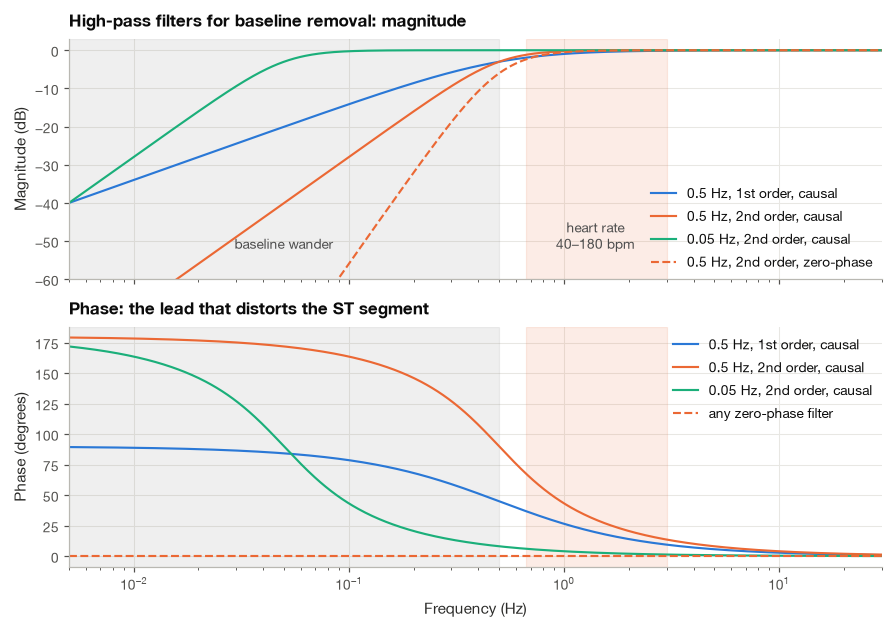

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(8, 5.6), sharex=True)
for ax in axes:
    ax.axvspan(0.005, 0.5, color="0.5", alpha=0.12)
    ax.axvspan(40 / 60, 3, color=C[1], alpha=0.12)
axes[0].text(0.05, -52, "baseline wander", ha="center", fontsize=9, color="0.3")
axes[0].text(1.4, -52, "heart rate\n40–180 bpm", ha="center", fontsize=9, color="0.3")
for (name, H), color in zip(resp.items(), (C[0], C[1], C[2])):
    axes[0].semilogx(f, 20 * np.log10(np.abs(H)), color=color, label=f"{name}, causal")
    axes[1].semilogx(f, np.degrees(np.angle(H)), color=color, label=f"{name}, causal")
axes[0].semilogx(f, 40 * np.log10(np.abs(resp["0.5 Hz, 2nd order"])), color=C[1], ls="--",
                 label="0.5 Hz, 2nd order, zero-phase")
axes[1].semilogx(f, np.zeros_like(f), color=C[1], ls="--", label="any zero-phase filter")
axes[0].set(ylim=(-60, 3), ylabel="Magnitude (dB)", title="High-pass filters for baseline removal: magnitude")
axes[1].set(ylabel="Phase (degrees)", xlabel="Frequency (Hz)", title="Phase: the lead that distorts the ST segment")
axes[0].legend(loc="lower right")
axes[1].legend(loc="upper right")
axes[1].set_xlim(0.005, 30)
plt.show()

The figure shows the dilemma. The 0.05 Hz filter leaves the heart-rate band untouched in both magnitude and phase, but it also leaves almost all of the baseline wander, which lies between about 0.05 and 0.5 Hz. The 0.5 Hz filters remove most of the wander but have a phase lead of 10 to 40 degrees across the heart-rate band. A zero-phase filter (dashed) keeps the steeper magnitude and has no phase at all.

(sec-12-2-3)=
## 12.2.3 Causal Versus Zero-Phase Butterworth Filters

### Step 5: Apply the filters to the clean reference

The cleanest way to see distortion is to filter the *noise-free* reference and compare the average beat before and after. A causal filter (`sosfilt`) processes the samples in order, as a bedside monitor must. A zero-phase filter (`sosfiltfilt`) runs the same filter forward and then backward over the recorded data, which cancels the phase and squares the magnitude response (Section 15.3). It needs the whole record, so it is available only offline.

In [11]:
filters = {
    "causal 0.5 Hz, 1st order": lambda x: signal.sosfilt(sos_c1, x),
    "causal 0.5 Hz, 2nd order": lambda x: signal.sosfilt(sos_c2, x),
    "zero-phase 0.5 Hz, 2nd order": lambda x: signal.sosfiltfilt(sos_c2, x),
}
clean_out = {name: fn(s) for name, fn in filters.items()}
rows = {name: score(y, s, s + 1e-12, r_peaks) for name, y in clean_out.items()}
print(pd.DataFrame(rows).T[["RMSE (uV)", "ST error (uV)", "ST bias (uV)"]].round(1))

                              RMSE (uV)  ST error (uV)  ST bias (uV)
causal 0.5 Hz, 1st order           23.6           16.0         -15.8
causal 0.5 Hz, 2nd order           35.7           27.2         -27.0
zero-phase 0.5 Hz, 2nd order        7.5            2.7           2.2


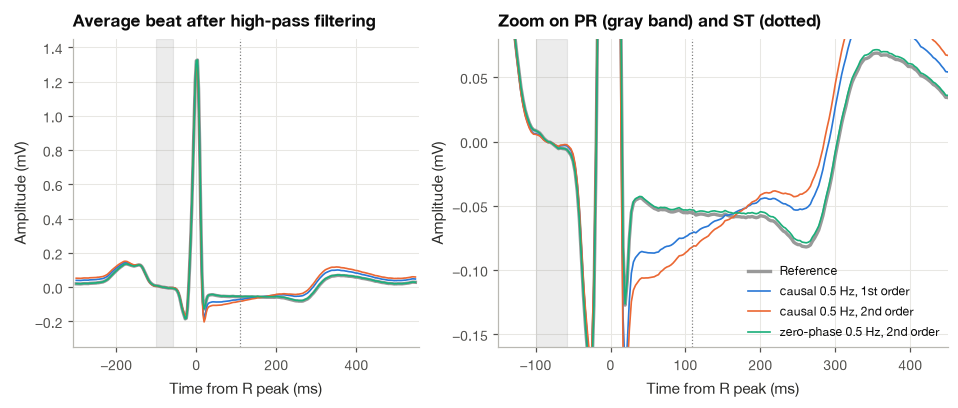

In [12]:
def average_beat(x, r_peaks, before=0.3, after=0.55):
    """Mean beat aligned on the R peak, shifted so that its PR level is zero."""
    segs = np.array([x[r - int(before * fs):r + int(after * fs)] for r in r_peaks])
    avg = segs.mean(axis=0)
    pr = avg[int(before * fs) + PR_WIN[0]:int(before * fs) + PR_WIN[1]].mean()
    return (np.arange(avg.size) / fs - before) * 1000, avg - pr


tb, avg_ref = average_beat(s, r_peaks)
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
for ax, ylim in zip(axes, [(-0.35, 1.45), (-0.16, 0.08)]):
    ax.plot(tb, avg_ref, color="0.6", lw=2.2, label="Reference")
    for (name, y), color in zip(clean_out.items(), (C[0], C[1], C[2])):
        ax.plot(tb, average_beat(y, r_peaks)[1], color=color, lw=1.1, label=name)
    ax.axvspan(1000 * PR_WIN[0] / fs, 1000 * PR_WIN[1] / fs, color="0.5", alpha=0.15)
    ax.axvline(1000 * ST_OFFSET / fs, color="0.5", lw=0.8, ls=":")
    ax.set(ylim=ylim, xlabel="Time from R peak (ms)", ylabel="Amplitude (mV)")
axes[0].set_title("Average beat after high-pass filtering")
axes[1].set(xlim=(-150, 450), title="Zoom on PR (gray band) and ST (dotted)")
axes[1].legend(loc="lower right", fontsize=8)
plt.show()

The numbers and the zoomed average beat agree. Both causal filters pull the ST segment down, by about 16 µV for the first-order filter and 27 µV for the second-order one, turning the 55 µV ST depression of record 100 into one of roughly 70 to 80 µV. The undershoot after the QRS is the visible trace of the phase lead derived above, and it grows with filter order because the phase lead does. The zero-phase filter changes the ST level by only about 2 µV. If you take one practical rule from this section, let it be this one: for offline analysis of ST segments, filter baseline wander with a zero-phase or linear-phase filter, never with a causal IIR high-pass above 0.05 Hz.

(sec-12-2-4)=
## 12.2.4 A Linear-Phase FIR High-Pass and the Decimation Trick

A linear-phase FIR filter delays every frequency by the same amount, so it preserves the shape of the beat exactly ([Section 9.1](../ch14_fir/01_linear_phase_fir.ipynb)) and can run in real time if we accept its delay. The difficulty is its length. Kaiser's empirical formula (Section 14.2) estimates the number of taps needed for a stopband attenuation of $A$ dB and a transition width $\Delta\Omega$ in radians per sample,

(eq-12-17)=
\begin{equation*}
N \approx \frac{A - 8}{2.285\,\Delta\Omega} + 1, \qquad \Delta\Omega = \frac{2\pi\,\Delta f}{f_s}. \tag{12.17}
\end{equation*}

The transition width in radians per sample is the transition width in hertz divided by the sampling rate. A baseline filter needs a transition only about half a hertz wide, which at $f_s = 360$ Hz is a tiny fraction of the band, so $N$ becomes large. For $A = 40$ dB and $\Delta f = 0.5$ Hz,

$$
N \approx \frac{32}{2.285 \times 2\pi \times 0.5/360} + 1 \approx 1609 \text{ taps},
$$

with a delay of $(N-1)/2 \approx 804$ samples, more than two seconds. Every output sample costs about 1600 multiplications.

Equation (12.17) also suggests the way out. If we reduce the sampling rate, the same transition width in hertz becomes a wider transition in radians per sample, and $N$ shrinks in proportion. Baseline wander lives below 1 Hz, so we can estimate it at a much lower rate:

1. Decimate the ECG by $D = 36$ (in two stages of 6, each with its own anti-aliasing filter) to $f_s/D = 10$ Hz.
2. Low-pass filter the decimated signal at 0.5 Hz with a short linear-phase FIR; at 10 Hz, equation (12.17) asks for only about 46 taps. The output is the baseline estimate.
3. Interpolate the baseline back to 360 Hz and subtract it from the original ECG.

Because the decimation and interpolation filters only have to separate 0.5 Hz from 5 Hz, they are short too.

### Step 6: Implement both versions and compare

In [13]:
n_full, beta_full = signal.kaiserord(40, 0.5 / (fs / 2))
h_full = signal.firwin(n_full | 1, 0.5, window=("kaiser", beta_full), pass_zero=False, fs=fs)

fs_low = fs / 36
n_low, beta_low = signal.kaiserord(40, 0.5 / (fs_low / 2))
h_low = signal.firwin(n_low | 1, 0.5, window=("kaiser", beta_low), fs=fs_low)
print(f"Kaiser length at 360 Hz: {n_full} taps; at {fs_low:.0f} Hz: {n_low} taps")


def fir_highpass_direct(x):
    """Linear-phase FIR high-pass at full rate; 'same' mode removes the (N-1)/2 delay."""
    return signal.fftconvolve(x, h_full, mode="same")


def fir_highpass_decimated(x):
    """Baseline by decimate (6 x 6) -> FIR low-pass at 10 Hz -> interpolate; then subtract."""
    y = signal.decimate(x, 6, ftype="fir", zero_phase=True)
    y = signal.decimate(y, 6, ftype="fir", zero_phase=True)
    base = np.convolve(y, h_low, mode="same")
    base = signal.resample_poly(signal.resample_poly(base, 6, 1), 6, 1)[:x.size]
    return x - base


y_direct = fir_highpass_direct(x6)
y_decim = fir_highpass_decimated(x6)
inner = slice(5 * fs, -5 * fs)
print(f"RMS difference between the two outputs: {1000 * np.std((y_direct - y_decim)[inner]):.1f} uV")

mults_direct = n_full * fs
mults_decim = 2 * (121 * fs / 6 + 121 * fs / 36) + n_low * fs_low   # decimation, interpolation, core FIR
print(f"Multiplications per second: direct {mults_direct:,.0f}, decimated about {mults_decim:,.0f} "
      f"({mults_direct / mults_decim:.0f} times fewer)")

Kaiser length at 360 Hz: 1609 taps; at 10 Hz: 46 taps
RMS difference between the two outputs: 1.2 uV
Multiplications per second: direct 579,240, decimated about 17,400 (33 times fewer)


The two outputs differ by only a few microvolts away from the ends of the record, while the decimated version needs more than thirty times fewer multiplications (the estimate counts the 121-tap filters that `decimate` uses by default, and assumes interpolation costs the same as decimation). The trick works whenever the band of interest is a small fraction of the sampling rate, which is exactly the situation for baseline wander.

(sec-12-2-5)=
## 12.2.5 Median-Filter Baseline Estimation

Filtering is not the only option. We can instead estimate the baseline directly and subtract it. A median filter replaces each sample by the median of its neighbors (Section 13.3), and its key property here is that it ignores any feature shorter than about half the window. The two-stage scheme used by {cite:t}`dechazal2004` exploits this twice:

(eq-12-18)=
\begin{equation*}
\hat{b}[n] = \operatorname{med}_{600}\big(\operatorname{med}_{200}(x)\big)[n], \qquad \hat{s}[n] = x[n] - \hat{b}[n], \tag{12.18}
\end{equation*}

where $\operatorname{med}_{L}$ is a median filter with a window of $L$ ms. The 200 ms filter removes the QRS complexes and P waves, which are narrower than 100 ms, and the 600 ms filter then removes the T waves, which last up to about 300 ms. What remains is a slowly varying estimate of the baseline. At 360 Hz the windows are 73 and 217 samples (odd lengths, so that each window has a center sample).

In [14]:
def median_baseline(x, fs):
    """Two-stage median baseline of equation (18.18): 200 ms then 600 ms windows."""
    w1 = int(0.2 * fs) | 1
    w2 = int(0.6 * fs) | 1
    return ndimage.median_filter(ndimage.median_filter(x, w1, mode="nearest"), w2, mode="nearest")


b_med = median_baseline(x6, fs)
b_spl = spline_baseline(x6, r_peaks)
true_b = x6 - s
for name, b in [("two-stage median", b_med), ("PR-knot spline", b_spl)]:
    err = (b - b.mean()) - (true_b - true_b.mean())
    print(f"{name:17s}: baseline estimation error RMS {1000 * np.std(err):5.1f} uV")

two-stage median : baseline estimation error RMS  31.2 uV
PR-knot spline   : baseline estimation error RMS   9.7 uV


(sec-12-2-6)=
## 12.2.6 Cubic-Spline Interpolation Through PR Knots

The most physiological approach goes straight to the clinical definition of the baseline. If the PR segment is the isoelectric reference, we can *measure* the baseline once per beat, in the PR segment, and interpolate between these measurements. The measured points are called **knots**, and the interpolating curve is a cubic spline: a chain of cubic polynomials, one between each pair of neighboring knots, joined so that the curve, its slope and its curvature are all continuous at every knot. These continuity conditions give a small tridiagonal system of linear equations for the polynomial coefficients, which `scipy.interpolate.CubicSpline` solves for us. A cubic is the lowest-order polynomial that allows this smoothness, and between knots about 0.8 s apart it can follow respiratory wander well but cannot follow anything faster.

We wrote this method in Step 2 as `spline_baseline`; its only extra requirement is a list of R-peak positions. Its weaknesses follow from the construction. It needs a reliable QRS detector; it measures each knot in a window of only 40 ms, so noise in that window passes straight into the baseline estimate; and it cannot see wander faster than about half the heart rate. The figure compares the two baseline estimates with the true added wander.

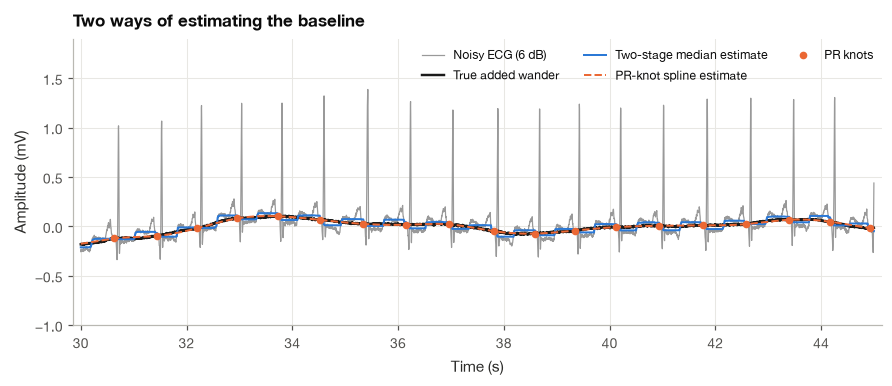

In [15]:
show = (t >= 30) & (t < 45)
tk, yk = pr_knots(x6, r_peaks)
in_win = (tk >= 30 * fs) & (tk < 45 * fs)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(t[show], x6[show], color="0.6", lw=0.8, label="Noisy ECG (6 dB)")
ax.plot(t[show], true_b[show], color="0.1", lw=1.6, label="True added wander")
ax.plot(t[show], b_med[show], color=C[0], lw=1.3, label="Two-stage median estimate")
ax.plot(t[show], b_spl[show], color=C[1], lw=1.3, ls="--", label="PR-knot spline estimate")
ax.plot(tk[in_win] / fs, yk[in_win], "o", color=C[1], ms=4, label="PR knots")
ax.set(xlabel="Time (s)", ylabel="Amplitude (mV)", ylim=(-1.0, 1.9),
       title="Two ways of estimating the baseline")
ax.legend(loc="upper right", ncols=3, fontsize=8)
plt.show()

Both estimates follow the wander closely. The spline passes through the knots and so tracks the PR level of every beat; the median estimate is smoother but sits slightly off the wander, because it is pulled toward whatever level the signal occupies for most of each beat. We will see in a moment that this small offset matters for the ST segment.

(sec-12-2-7)=
## 12.2.7 Simple Alternatives: Moving Average and Polynomial Fits

Two even simpler estimates appear in many codebases. The first is a **moving average** over about one heartbeat. Averaging over a full beat smears each QRS, P and T wave into a small constant, so what varies from window to window is mainly the baseline. Subtracting it is equivalent to the high-pass filter $1 - H_{\text{MA}}$, where $H_{\text{MA}}$ is the moving-average response of Section 13.3 with nulls at multiples of $1/T_w$ for a window of $T_w$ seconds. With $T_w = 1$ s, the nulls fall at 1, 2, 3 Hz, so the estimate is unbiased only when the heart rate is near 60 beats per minute. The second is a **polynomial fit**: within each ten-second strip, fit a low-order polynomial by least squares and subtract it. This is popular for short resting ECGs, which are usually exactly ten seconds long, but a cubic cannot follow more than one or two undulations per strip.

In [16]:
def moving_average_baseline(x, fs, seconds=1.0):
    """Baseline as the centered moving average over the given window."""
    return ndimage.uniform_filter1d(x, int(seconds * fs), mode="nearest")


def polynomial_baseline(x, fs, seconds=10.0, order=3):
    """Least-squares polynomial of the given order fitted to each strip of the given length."""
    base = np.empty_like(x)
    L = int(seconds * fs)
    for start in range(0, x.size, L):
        seg = x[start:start + L]
        n = np.arange(seg.size)
        base[start:start + L] = np.polyval(np.polyfit(n, seg, order), n)
    return base

(sec-12-2-8)=
## 12.2.8 Comparing the Methods

### Step 7: Run every method at every noise level

We now apply eight methods to the reference without noise (to measure pure distortion) and at the four input SNRs. I drop the first-order causal filter, which we have already examined, and keep the direct FIR only through its cheaper decimated twin.

In [17]:
methods = {
    "causal Butterworth 0.5 Hz": lambda x: signal.sosfilt(sos_c2, x),
    "zero-phase Butterworth 0.5 Hz": lambda x: signal.sosfiltfilt(sos_c2, x),
    "zero-phase Butterworth 0.05 Hz": lambda x: signal.sosfiltfilt(sos_005, x),
    "linear-phase FIR 0.5 Hz (decimated)": fir_highpass_decimated,
    "two-stage median": lambda x: x - median_baseline(x, fs),
    "PR-knot cubic spline": lambda x: x - spline_baseline(x, r_peaks),
    "moving average 1 s": lambda x: x - moving_average_baseline(x, fs),
    "polynomial, order 3 per 10 s": lambda x: x - polynomial_baseline(x, fs),
}

records = []
for snr in [np.inf] + snr_levels:
    x = s + 0 * bw if snr == np.inf else noisy[snr]
    for name, fn in methods.items():
        m = score(fn(x), s, x + 1e-9 * (snr == np.inf), r_peaks)
        records.append({"method": name, "SNR in (dB)": snr, **m})
results = pd.DataFrame(records)

rmse_table = results.pivot(index="method", columns="SNR in (dB)", values="RMSE (uV)")
st_table = results.pivot(index="method", columns="SNR in (dB)", values="ST error (uV)")
order = list(methods)
print("RMSE (uV)")
print(rmse_table.loc[order, [np.inf] + snr_levels].round(0))

RMSE (uV)
SNR in (dB)                           inf    12.0   6.0    0.0   -6.0 
method                                                                
causal Butterworth 0.5 Hz             36.0   37.0   39.0   46.0   67.0
zero-phase Butterworth 0.5 Hz          7.0    9.0   11.0   19.0   35.0
zero-phase Butterworth 0.05 Hz         6.0   46.0   91.0  182.0  362.0
linear-phase FIR 0.5 Hz (decimated)    7.0    8.0   11.0   19.0   35.0
two-stage median                      30.0   30.0   31.0   34.0   41.0
PR-knot cubic spline                   0.0    5.0   10.0   19.0   39.0
moving average 1 s                    13.0   14.0   16.0   22.0   37.0
polynomial, order 3 per 10 s           6.0   24.0   47.0   93.0  186.0


In [18]:
print("ST error (uV)")
print(st_table.loc[order, [np.inf] + snr_levels].round(0))

ST error (uV)
SNR in (dB)                           inf    12.0   6.0    0.0   -6.0 
method                                                                
causal Butterworth 0.5 Hz             27.0   27.0   28.0   30.0   38.0
zero-phase Butterworth 0.5 Hz          3.0    4.0    6.0   11.0   22.0
zero-phase Butterworth 0.05 Hz         0.0    7.0   13.0   26.0   52.0
linear-phase FIR 0.5 Hz (decimated)    2.0    3.0    6.0   11.0   22.0
two-stage median                      46.0   46.0   45.0   47.0   53.0
PR-knot cubic spline                   0.0    3.0    6.0   12.0   25.0
moving average 1 s                     7.0    8.0    9.0   13.0   23.0
polynomial, order 3 per 10 s           1.0    7.0   13.0   26.0   51.0


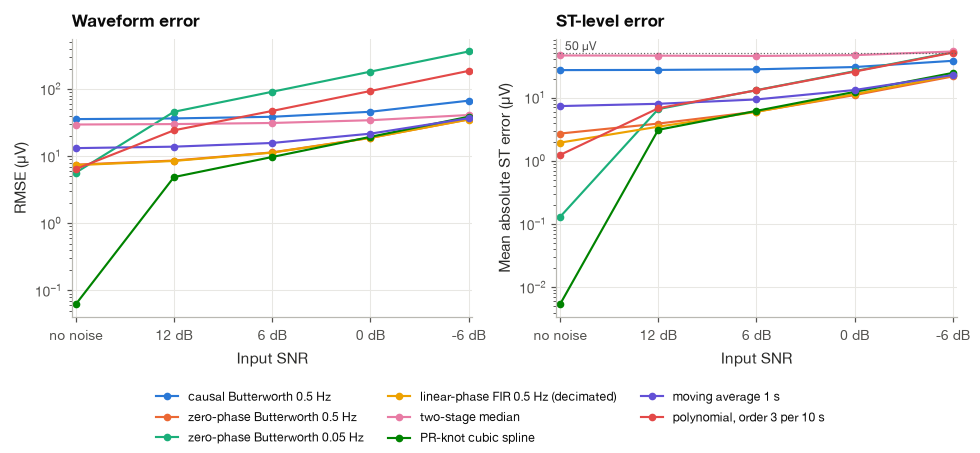

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(8.8, 4.0))
x_pos = np.arange(len(snr_levels) + 1)
x_labels = ["no noise"] + [f"{v} dB" for v in snr_levels]
for k, name in enumerate(order):
    axes[0].plot(x_pos, rmse_table.loc[name, [np.inf] + snr_levels], "-o", color=C[k], ms=4, label=name)
    axes[1].plot(x_pos, st_table.loc[name, [np.inf] + snr_levels], "-o", color=C[k], ms=4)
axes[0].set(yscale="log", ylabel="RMSE (µV)", title="Waveform error")
axes[1].set(yscale="log", ylabel="Mean absolute ST error (µV)", title="ST-level error")
axes[1].axhline(50, color="0.4", lw=0.8, ls=":")
axes[1].text(0.05, 56, "50 µV", fontsize=8, color="0.3")
for ax in axes:
    ax.set_xticks(x_pos, x_labels)
    ax.set_xlabel("Input SNR")
fig.legend(loc="outside lower center", ncols=3, fontsize=8)
plt.show()

### Step 8: Read the results

The comparison sorts the methods into clear groups.

- The **PR-knot spline** is best on both measures at every noise level, and it is the only method whose error stays well below 50 µV in the ST level even at $-6$ dB. Part of its lead is the home advantage noted in Step 2, but the margin over the next best methods is large, especially at moderate noise.
- The **zero-phase Butterworth** and the **linear-phase FIR** at 0.5 Hz behave almost identically, as they should: same cutoff, no phase distortion. They introduce almost no distortion on the clean signal and degrade gracefully, with ST errors of tens of microvolts only when the wander is stronger than the ECG.
- The **0.05 Hz filter** distorts nothing but also removes little, so its error grows rapidly with the noise. It is the right choice for a causal diagnostic recorder, and the wrong one when strong wander must be removed offline.
- The **causal 0.5 Hz filter** has a systematic ST error of about 27 µV even without noise, the phase distortion we saw in Section 12.2.3.
- The **two-stage median** has an RMSE comparable to the best filters, but its ST error is about 46 µV at every noise level, nearly the size of the ST depression itself. The bias comes from the mechanism described above: within each 600 ms window, the median settles on the level the signal occupies most of the time, and in record 100 the long ST–T segment sits about 55 µV below the PR level, so the baseline estimate is pulled toward it. De Chazal and colleagues used this baseline for beat *classification*, where such a bias is irrelevant; for ST measurement it is not acceptable.
- The **moving average** is a reasonable quick fix, and the **polynomial fit** works only while the wander is gentle.

My recommendation follows directly. For offline analysis where the R peaks are known, use the PR-knot spline, or a zero-phase 0.5 to 0.67 Hz high-pass if you prefer a method that does not depend on beat detection. For real-time monitoring, use a linear-phase FIR with the decimation trick if a delay of a second or two is acceptable, and a causal IIR filter only at 0.05 Hz when ST levels matter. Median baselines are fine for detection and classification but should not be used before ST measurement.

```{important}
Always check what a filter does to the *clean* signal, not just how much noise it removes. In our test the two-stage median and the causal 0.5 Hz filter both look reasonable by RMSE, yet both shift the ST level by an amount that could change a clinical reading.
```

## Summary

Baseline wander lives mostly below 0.5 Hz, while the ECG's lowest harmonic lies at the heart rate, which can be as low as 0.67 Hz. A high-pass filter can separate the two only if its cutoff stays below the heart-rate fundamental and if it does not distort the phase. The phase lead of a causal high-pass, $\arctan(f_c/f)$ for a first-order filter, shifts the slow components of the beat earlier than the fast ones and pulls the ST segment down, by about 16 to 27 µV in our test for a 0.5 Hz filter; this is why the diagnostic recommendation for causal filters is 0.05 Hz, while zero-phase and linear-phase filters may go up to 0.67 Hz {cite:p}`kligfield2007`. Linear-phase FIR high-pass filters need thousands of taps at the full sampling rate, but estimating the baseline at a decimated rate cuts the cost more than thirtyfold with practically identical results.

Estimating the baseline and subtracting it is the other strategy. A cubic spline through PR-segment knots follows the clinical definition of the isoelectric line and gave the smallest waveform and ST errors in our test, at the price of needing R-peak positions. The two-stage median filter is simple and needs no detector, but it biases the ST level toward the ST–T segment. These results feed directly into the complete pipeline of Section 18.5, and the R-peak detection that the spline needs is the subject of Section 19.1.

## Exercises

1. Using equation (12.15), compute the phase lead and the corresponding time shift of a first-order 0.5 Hz high-pass at the fundamental and at the second harmonic of a heart rate of 50 beats per minute. Repeat for a cutoff of 0.05 Hz. Which harmonics are shifted by more than 5 ms in each case?
2. Show that applying a filter with frequency response $H(e^{j\Omega})$ forward and then backward gives the overall response $|H(e^{j\Omega})|^2$. What is the $-3$ dB frequency of a forward–backward second-order Butterworth high-pass designed with a 0.5 Hz cutoff?
3. Use equation (12.17) to find the FIR length for a high-pass with a 0.3 Hz transition band and 50 dB attenuation at 500 Hz. Then choose a decimation factor and estimate the cost of the decimation approach. How much delay does each version introduce?
4. Repeat the comparison of Section 12.2.8 with the median windows changed to 150 and 450 ms, and to 250 and 800 ms. How does the ST bias change, and why?
5. Replace the annotated R peaks in the spline method by peaks detected with `scipy.signal.find_peaks` on a 5–15 Hz band-passed version of the noisy signal. How much do the RMSE and ST error grow at 0 dB? What happens to the spline when a beat is missed?
6. Simulate an exercise ECG with a heart rate that rises from 60 to 150 beats per minute and baseline wander from `bw` at $-6$ dB. Compare the 1 s moving-average baseline with the spline and with the zero-phase 0.5 Hz filter as the heart rate changes, and explain the behavior of the moving average using the position of its nulls.

## Further Reading

The low-frequency cutoff recommendations and their justification in terms of phase distortion are given by {cite:t}`kligfield2007`. {cite:t}`sornmo2005` (Chapter 5) give a thorough treatment of baseline wander removal, including linear filtering with sampling-rate alteration and spline-based methods, and {cite:t}`clifford2006` discuss baseline correction within complete ECG processing chains. The two-stage median filter used here comes from the heartbeat classification study of {cite:t}`dechazal2004`, and the forward–backward filtering used for the zero-phase filters is analyzed by {cite:t}`gustafsson1996`.